# ChromData: the data model

`ChromData` is the one object every U-Chrom module reads and writes: cells › traces › spots, each spot a
3-D position of one genomic locus, all spots pointing into one shared locus axis (`bins`).  This tutorial
walks through the format 2.x model on a real chromatin-tracing dataset: how to build an object, the locus
axis, per-locus vs per-spot signals, the cell and trace tables, typed interval tables, results with
provenance, subsetting, on-demand distances and cell positions.

**Modules**: `chromdata` (`ChromData`, `chromdata.intervals`, `chromdata.results`); one call to `uchrom`
(`uc.tl.call_tads`) shows how analysis functions fill `intervals` and `results`.
**Data**: Takei et al. 2021, *Nature* 590:344 (DNA seqFISH+, 201 mouse ES cells, 20 chromosomes × 60 loci
of 25 kb), 4DN FOF-CT core table `4DNFIHF3JCBY.csv` with its cell table `4DNFIFINA2U9.csv` and nascent-RNA
spot table `4DNFIJ52NVDV.csv` (see `example-data/README.md`).  **Runtime**: about 15 s.
Storage on disk (`.chromdata.zarr`, backed reads, linked contact maps, the atlas) is the subject of
`chromdata_stores`.

In [1]:
import itertools
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import chromdata
from chromdata import ChromData

plt.rcParams["figure.dpi"] = 90


def find_repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "example-data" / "README.md").exists():
            return p
    raise FileNotFoundError("run this notebook inside the U-Chrom repository")


REPO = find_repo_root(); DATA = REPO / "example-data"; OUT = REPO / "tutorials" / "_out"; OUT.mkdir(exist_ok=True)
OUT = OUT / "chromdata_basics"; OUT.mkdir(exist_ok=True)

CORE = DATA / "4DNFIHF3JCBY.csv"     # FOF-CT core table, 22 MB (4DN public S3)
CELLS = DATA / "4DNFIFINA2U9.csv"    # FOF-CT cell table (in the repository)
RNA = DATA / "4DNFIJ52NVDV.csv"      # FOF-CT nascent-RNA spot table (in the repository)
if not CORE.exists():                # = python example-data/download_data.py --takei
    import urllib.request
    print(f"downloading {CORE.relative_to(REPO)} (22 MB) from the 4DN public S3 bucket")
    urllib.request.urlretrieve("https://4dn-open-data-public.s3.amazonaws.com/fourfront-webprod/wfoutput/"
                               "e699334e-fb34-4a0e-8ef6-670b2099831a/4DNFIHF3JCBY.csv", CORE)
print("chromdata", chromdata.__version__)

chromdata 0.1.0


## The model at a glance

| axis | one row per | attributes |
|---|---|---|
| spots | detected locus of one trace | `coords` (n_spots × 3), `spots` (`bin_id`, `trace_id`, `cell_id`, …), `spot_tracks`, `layers` |
| bins | locus, shared by all cells | `bins` (`chrom`, `start`, `end`), `bin_tracks`, `binm`, `intervals` |
| cells | cell | `cells` (incl. cell positions), `cellm`, `cell_shapes`, `points` (RNA spots, …) |
| traces | chromatin fibre (one homolog of one chromosome) | `traces` |
| – | analysis output | `results` (with provenance), `uns` |

Pairwise distance matrices are never stored (they are per trace and O(n²)); contact maps and RNA matrices
stay in their own files and are *linked* (see `chromdata_stores`).

## Building a ChromData from a spot table

The minimum is `coords` (n_spots × 3) and a `spots` table with `trace_id` and either the loci
(`chrom`, `start`, `end`) — the locus axis `bins` is then derived — or a `bin_id` into a `bins` table you
pass.  Here we read the spots of the first cell straight from the FOF-CT core table with pandas (the
`##columns=` header line names the columns) and build the object by hand.

In [2]:
with open(CORE) as fh:
    header = list(itertools.takewhile(lambda line: line.lstrip('"').startswith("#"), fh))
names = next(l for l in header if l.startswith("##columns=")).split("=", 1)[1].strip().strip(",").strip("()").split(",")
print(len(header), "header lines; columns:", names)

table = pd.read_csv(CORE, skiprows=len(header), header=None, names=names, nrows=3000)
one = table[table["Cell_ID"] == "0_1"]
spots = pd.DataFrame({"chrom": one["Chrom"], "start": one["Chrom_Start"], "end": one["Chrom_End"],
                      "trace_id": one["Trace_ID"], "cell_id": one["Cell_ID"], "spot_id": one["Spot_ID"]})
mini = ChromData(one[["X", "Y", "Z"]].to_numpy(), spots, uns={"genome_assembly": "mm10", "xyz_unit": "micron"})
mini

15 header lines; columns: ['Spot_ID', 'Trace_ID', 'X', 'Y', 'Z', 'Chrom', 'Chrom_Start', 'Chrom_End', 'Cell_ID', 'Extra_Cell_ROI_ID']


ChromData: n_spots=1473, n_traces=39, n_cells=1, n_bins=953
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'spot_id', 'bin_id']
  uns:     ['genome_assembly', 'xyz_unit']

The constructor derived `bins` from the distinct loci (sorted by chromosome, start, end) and gave every spot a
`bin_id`.  Two spots of different homologs (traces `…_0` and `…_1`) at the same locus share a bin:

In [3]:
display(mini.bins.head(3))
mini.spots.head(3)

,chrom,start,end
bin_id,,,
0,chr1,135625000,135650000
1,chr1,135650000,135675000
2,chr1,135700000,135725000


,chrom,start,end,trace_id,cell_id,spot_id,bin_id
0,chr1,135625000,135650000,0_1_1_0,0_1,705144,0
1,chr1,135650000,135675000,0_1_1_0,0_1,705145,1
2,chr1,135650000,135675000,0_1_1_1,0_1,705146,1


The same object can be built from `bin_id` + `bins=`; `chrom` / `start` / `end` are then filled in from
`bins`.  Pass `bins=` whenever objects must share one locus axis — this cell alone saw only 953 of the 1,200
imaged loci.  Missing required columns fail at construction:

In [4]:
mini2 = ChromData(mini.coords, mini.spots[["bin_id", "trace_id", "cell_id", "spot_id"]], bins=mini.bins)
print("same spots:", mini2.spots_with_loci()[mini.spots.columns].equals(mini.spots))
try:
    ChromData(mini.coords, spots.drop(columns="trace_id"))
except ValueError as err:
    print("ValueError:", err)

same spots: True
ValueError: spots missing required column: 'trace_id'


## Loading the whole dataset with `from_fofct`

`ChromData.from_fofct` reads the core table and, optionally, its companion tables: the cell table becomes
`cells` (cell-table centroids are registered as cell positions) and the RNA spot table becomes
`points["rna"]`.  The `##` header lines go to `uns`.

In [5]:
t0 = time.perf_counter()
cd = ChromData.from_fofct(CORE, cell_table=CELLS, rna_table=RNA)
print(f"read in {time.perf_counter() - t0:.2f} s")
print(cd.n_cells, "cells,", cd.n_traces, "traces,", cd.n_spots, "spots,", cd.n_bins, "bins on", len(cd.chroms), "chromosomes")
print("uns:", {k: cd.uns[k] for k in ("genome_assembly", "xyz_unit")}, "+", [k for k in cd.uns if k not in ("genome_assembly", "xyz_unit")])

read in 0.34 s
201 cells, 8285 traces, 316995 spots, 1200 bins on 20 chromosomes
uns: {'genome_assembly': 'GRCm38/mm10', 'xyz_unit': 'micron'} + ['fofct_header', 'fofct_companions', 'cell_spatial']


A trace here is one homolog of one chromosome in one cell (`Trace_ID` = `<fov>_<cell>_<chromosome>_<homolog>`).
Spots per trace and traces per cell:

In [6]:
per_trace = cd.spots.groupby("trace_id", observed=True).size()
per_cell = cd.spots.groupby("cell_id", observed=True)["trace_id"].nunique()
dup = cd.spots.duplicated(["trace_id", "bin_id"]).sum()
print(f"spots per trace: median {per_trace.median():.0f} of 60 loci (range {per_trace.min()}-{per_trace.max()})")
print(f"traces per cell: median {per_cell.median():.0f} (2 homologs x 20 chromosomes = 40)")
print(f"{dup:,} spots ({dup / cd.n_spots:.0%}) repeat a locus already detected in the same trace")

spots per trace: median 39 of 60 loci (range 1-154)
traces per cell: median 41 (2 homologs x 20 chromosomes = 40)
35,432 spots (11%) repeat a locus already detected in the same trace


## The locus axis: `bins` and `spots.bin_id`

`bins` has one row per locus (index `bin_id`), shared by every cell; each spot points at one bin.  The
`chrom` / `start` / `end` columns of `spots` are derived from `bins` (they are not stored on disk);
`spots_with_loci()` is the stable way to get them.  `chrom`, `trace_id` and `cell_id` are categoricals.

In [7]:
display(cd.bins.groupby("chrom", observed=True).size().describe()[["count", "min", "max"]].rename("loci per chromosome").to_frame().T)
print({c: f"category ({len(t.categories)} values)" if isinstance(t, pd.CategoricalDtype) else str(t)
       for c, t in cd.spots.dtypes.items()})
as_object = cd.spots.astype({c: object for c in ("chrom", "trace_id", "cell_id")})
print(f"spots table: {cd.spots.memory_usage(deep=True).sum() / 1e6:.1f} MB with categoricals, "
      f"{as_object.memory_usage(deep=True).sum() / 1e6:.1f} MB with Python strings")

,count,min,max
loci per chromosome,20.0,60.0,60.0


{'chrom': 'category (20 values)', 'start': 'int64', 'end': 'int64', 'trace_id': 'category (8285 values)', 'spot_id': 'int64', 'cell_id': 'category (201 values)', 'extra_cell_roi_id': 'int64', 'bin_id': 'int64'}
spots table: 14.4 MB with categoricals, 64.6 MB with Python strings


To change loci, edit `cd.bins` (or edit the spot loci and call `cd.rebuild_bins()`); the derived spot
columns cannot disagree with `bins` — the constructor checks it.

## Per-locus and per-spot signals: `bin_tracks`, `spot_tracks`, `binm`

A value that belongs to a locus (bulk ChIP, GC content, a detection rate) is a column of `bin_tracks`
(n_bins rows); a value measured on one spot (IF intensity, a per-spot distance) is a column of
`spot_tracks` (n_spots rows).  Two real examples: the fraction of traces in which each locus was detected,
and each spot's distance to the centre of its trace.

In [8]:
chrom_of_bin = cd.bins["chrom"].astype(str)
traces_per_chrom = cd.spots.groupby("chrom", observed=True)["trace_id"].nunique()
traces_per_bin = cd.spots.groupby("bin_id")["trace_id"].nunique().reindex(range(cd.n_bins), fill_value=0)
cd.bin_tracks["detection_rate"] = traces_per_bin.to_numpy() / chrom_of_bin.map(traces_per_chrom).to_numpy()

trace_code = cd.spots["trace_id"].cat.codes.to_numpy()
centre = pd.DataFrame(cd.coords).groupby(trace_code).transform("mean").to_numpy()
cd.spot_tracks["dist_to_trace_centre_um"] = np.linalg.norm(cd.coords - centre, axis=1)

print(cd.track_names())
print(f"detection rate per locus: median {cd.bin_tracks['detection_rate'].median():.2f} "
      f"(range {cd.bin_tracks['detection_rate'].min():.2f}-{cd.bin_tracks['detection_rate'].max():.2f})")
cd.tracks_spot_view().head(3)

{'bin': ['detection_rate'], 'spot': ['dist_to_trace_centre_um']}
detection rate per locus: median 0.57 (range 0.01-0.80)


,detection_rate,dist_to_trace_centre_um
0,0.438679,0.465144
1,0.431604,0.496312
2,0.431604,0.783389


`tracks_spot_view()` broadcasts the bin tracks to the spots (through `bin_id`) next to the spot tracks — the
view analysis code often wants.  (The 1.x attribute `cd.tracks` is a deprecated alias of that view; new
code uses `bin_tracks` / `spot_tracks`.)

`binm` holds per-locus arrays with more than one value per bin.  Each chromosome here has 60 loci, so the
population median distance map of a chromosome fits as rows of a `(n_bins, 60)` array: row *i* holds the
median distance of locus *i* to every locus of its chromosome (spots of the same locus in a trace are
averaged first).

In [9]:
def median_distance_map(sub, bin_ids):
    # population median distance (um) between the loci bin_ids of one chromosome
    local = np.searchsorted(bin_ids, sub.spots["bin_id"].to_numpy())
    t = sub.spots["trace_id"].cat.remove_unused_categories().cat.codes.to_numpy()
    pos = np.zeros((t.max() + 1, len(bin_ids), 3)); n = np.zeros((t.max() + 1, len(bin_ids)))
    np.add.at(pos, (t, local), sub.coords); np.add.at(n, (t, local), 1)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)    # loci a trace missed / pairs never seen: NaN
        pos /= n[..., None]
        d = np.linalg.norm(pos[:, :, None] - pos[:, None, :], axis=-1)
        return np.nanmedian(d, axis=0)

t0 = time.perf_counter()
med = np.full((cd.n_bins, 60), np.nan)
for chrom in cd.chroms:
    ids = np.flatnonzero(chrom_of_bin.to_numpy() == chrom)
    med[ids] = median_distance_map(cd.get_chrom(chrom), ids)
cd.binm["median_distance_um"] = med
print(f"binm['median_distance_um'] {med.shape} in {time.perf_counter() - t0:.1f} s; "
      f"neighbouring loci (25 kb apart): median {np.nanmedian(np.diagonal(med.reshape(20, 60, 60), 1, 1, 2)):.2f} um")

binm['median_distance_um'] (1200, 60) in 1.2 s; neighbouring loci (25 kb apart): median 0.18 um


## Cells, traces, layers and points

`cells` is indexed by `cell_id`; here it holds the cell table (nucleus area, mRNA counts per gene as
`rna.<gene>`, the authors' QC flag `keep1`).  `cellm` holds per-cell arrays whose rows follow `cells` —
e.g. a PCA of the log-normalised mRNA counts:

In [10]:
genes = [c for c in cd.cells.columns if c.startswith("rna.")]
counts = cd.cells[genes].to_numpy(float)
logx = np.log1p(counts / counts.sum(1, keepdims=True) * 1e4)
u, s, _ = np.linalg.svd(logx - logx.mean(0), full_matrices=False)
cd.cellm["rna_pca"] = u[:, :10] * s[:10]
print(f"{len(genes)} genes; cellm:", {k: v.shape for k, v in cd.cellm.items()},
      f"; PC1-2 explain {(s[:2] ** 2).sum() / (s ** 2).sum():.0%} of the variance")
cd.cells[["keep1", "nucleus_area_um2", "rna.Nanog", "rna.Zfp42"]].head(3)

45 genes; cellm: {'rna_pca': (201, 10)} ; PC1-2 explain 35% of the variance


,keep1,nucleus_area_um2,rna.Nanog,rna.Zfp42
cell_id,,,,
0_1,0,242.161034,0.0,21.0
0_2,0,158.668204,1.0,95.0
0_3,0,203.735236,0.0,41.0


`traces` is the per-trace table, indexed by `trace_id`.  We fill it from the data: chromosome, homolog
(the last field of the id: 0 or 1 for most traces, -1, 2 or 3 for some, as deposited), number of spots and
radius of gyration.

In [11]:
d2 = cd.spot_tracks["dist_to_trace_centre_um"].to_numpy() ** 2
g = pd.DataFrame({"trace_id": cd.spots["trace_id"].astype(str), "chrom": cd.spots["chrom"].astype(str), "d2": d2})
traces = g.groupby("trace_id").agg(chrom=("chrom", "first"), n_spots=("d2", "size"), rg_um=("d2", "mean"))
traces["rg_um"] = np.sqrt(traces["rg_um"])
traces["homolog"] = traces.index.str.rsplit("_", n=1).str[1].astype(int)
cd.traces = traces
print(cd.traces["homolog"].value_counts().to_dict())
cd.traces.head(3)

{0: 3987, 1: 3551, -1: 659, 2: 83, 3: 5}


,chrom,n_spots,rg_um,homolog
trace_id,,,,
0_10_10_0,chr10,33,0.499358,0
0_10_10_1,chr10,45,0.373785,1
0_10_11_0,chr11,50,0.336504,0


`layers` are alternative coordinate sets with the shape of `coords` (raw / drift-corrected / a second
model).  `points` are non-genomic 3-D points in the same frame, here the 3,335 nascent-RNA spots, linked
to cells by `cell_id`.

In [12]:
cd.layers["trace_centred"] = cd.coords - centre
print({k: v.shape for k, v in cd.layers.items()})
print(len(cd.points["rna"]), "RNA spots; most frequent:", cd.points["rna"]["gene"].value_counts().head(3).to_dict())
cd.points["rna"][["x", "y", "z", "gene", "cell_id"]].head(3)

{'trace_centred': (316995, 3)}
3335 RNA spots; most frequent: {'Lgr4': 457, 'Actb': 454, 'Rpl5': 359}


,x,y,z,gene,cell_id
0,169.853,26.619,3.386,Auts2,0_1
1,152.599,24.696,2.371,Auts2,0_2
2,32.609,78.165,3.294,Auts2,0_10


## Interval tables: `intervals`

`cd.intervals` maps a key to an `IntervalTable`, a DataFrame with a declared `kind`:
`domain` (`chrom, start, end`: TADs, domains), `pair` (`chrom1 … end2`: loops), `peak` and `segment`
(`… label`: compartments).  Tables are validated when stored.  The imaged regions make a small `domain` table:

In [13]:
regions = cd.bins.groupby("chrom", observed=True).agg(start=("start", "min"), end=("end", "max")).reset_index()
cd.intervals.add("regions.imaged", regions, kind="domain")
print(cd.intervals)
try:
    cd.intervals.add("broken", regions.assign(end=regions["start"] - 1), kind="domain")
except ValueError as err:
    print("ValueError:", err)
cd.intervals["regions.imaged"].head(3)

IntervalStore({'regions.imaged': <domain, 20 rows>})
ValueError: domain intervals must satisfy end >= start


,chrom,start,end
0,chr1,135600000,137100000
1,chr10,75400000,76900000
2,chr11,97425000,98925000


## Results with provenance: `results`

`cd.results` is a `ResultsStore`: `cd.results[key]` is the value, `cd.results.record(key)` the value with
its provenance (producing function, parameters, inputs, package version, time).  Values must be storable
(DataFrame / Series, numeric array, dict of those, JSON scalars); anything else fails at assignment, not at
`write()`.

In [14]:
long = cd.traces[cd.traces["n_spots"] >= 30]
rg = long.groupby("chrom")["rg_um"].median()
cd.results.set("rg.median_by_chrom", rg, function="tutorials/chromdata_basics.ipynb",
               params={"min_spots": 30}, inputs={"n_traces": len(long)})
print(cd.results)
print(cd.results.record("rg.median_by_chrom").provenance)
print(f"median Rg per chromosome (1.5 Mb regions): {rg.min():.2f}-{rg.max():.2f} um")
try:
    cd.results["not_storable"] = {1, 2, 3}
except TypeError as err:
    print("TypeError:", str(err)[:90], "...")

ResultsStore({'rg.median_by_chrom': <table>})
{'kind': 'table', 'function': 'tutorials/chromdata_basics.ipynb', 'params': {'min_spots': 30}, 'inputs': {'n_traces': 5815}, 'uchrom_version': '0.2.0', 'created_utc': '2026-10-06T21:21:25+00:00'}
median Rg per chromosome (1.5 Mb regions): 0.29-0.44 um
TypeError: results['not_storable']: cannot store a value of type set in cd.results. Supported: DataFr ...


Analysis functions of `uchrom` follow one convention: they store their table under `key_added`
(`"tads.arcfish"` here) with provenance, and interval-like outputs also appear in `cd.intervals` (the same
object, typed, with `source_result` pointing back to the record).  ArcFISH TAD calling on chr3:

In [15]:
import uchrom as uc

t0 = time.perf_counter()
tads = uc.tl.call_tads(cd, chrom="chr3", device="cpu")
print(f"call_tads: {time.perf_counter() - t0:.1f} s, {len(tads)} domains over {tads['level'].nunique()} levels")
rec = cd.results.record("tads.arcfish")
print(cd.intervals)
print("kind:", cd.intervals["tads.arcfish"].kind, "| source_result:", cd.intervals["tads.arcfish"].source_result)
print("function:", rec.function, "| params:", rec.params)
tads[tads["level"] == 1]

call_tads: 1.8 s, 9 domains over 3 levels
IntervalStore({'regions.imaged': <domain, 20 rows>, 'tads.arcfish': <domain, 9 rows>})
kind: domain | source_result: tads.arcfish
function: uchrom.strc.tad.call_tads_by_pval | params: {'window_bp': 100000.0, 'fdr_cutoff': 0.1, 'hierarchical': True, 'max_levels': 4, 'prominence': 0.0, 'distance': 1, 'k_sigma': 4.0, 'frac': 0.1}


,chrom,start,end,level,score,pval,fdr
0,chr3,7675000,8550000,1,2.782943,0.001648,0.028022
1,chr3,8550000,8925000,1,2.782943,0.001648,0.028022
2,chr3,8925000,9050000,1,1.809940,0.015490,0.097475
3,chr3,9050000,9325000,1,1.764433,0.017202,0.097475


`IntervalTable.to_bins` projects intervals onto the locus axis — for example the level-1 domain of every
chr3 locus as a bin track (-1 where no domain overlaps):

In [16]:
level1 = cd.intervals["tads.arcfish"].query("level == 1")
cd.bin_tracks["tad_chr3_level1"] = level1.to_bins(cd.bins, how="id").to_numpy()
cd.bin_tracks.loc[chrom_of_bin == "chr3", "tad_chr3_level1"].value_counts().sort_index().to_dict()

{0: 29, 1: 15, 2: 5, 3: 11}

## Subsetting: `get_cell`, `get_cells`, `get_trace`, `get_chrom`, `cd[rows]`

Every subset is a new `ChromData` (the original is not modified).  Cell- and trace-level tables follow the
spots (`cells`, `cellm`, `traces`, `points`), the locus axis does not: `bins` and the per-locus data are kept
whole, so subsets of one dataset always share one axis.

In [17]:
def summary(name, x):
    return {"subset": name, "n_spots": x.n_spots, "n_traces": x.n_traces, "n_cells": x.n_cells,
            "traces rows": len(x.traces), "rna points": len(x.points["rna"]),
            "n_bins": x.n_bins}

qc = cd.cells.index[cd.cells["keep1"] == 1]
subsets = {
    "cd": cd,
    'cd.get_cell("0_1")': cd.get_cell("0_1"),
    "cd.get_cells(keep1 == 1)": cd.get_cells(qc),
    'cd.get_trace("0_1_3_0")': cd.get_trace("0_1_3_0"),
    'cd.get_chrom("chr3")': cd.get_chrom("chr3"),
    "cd[dist to centre < 0.5 um]": cd[cd.spot_tracks["dist_to_trace_centre_um"].to_numpy() < 0.5],
    "cd[:1000]": cd[:1000],
}
pd.DataFrame([summary(k, v) for k, v in subsets.items()]).set_index("subset")

,n_spots,n_traces,n_cells,traces rows,rna points,n_bins
subset,,,,,,
cd,316995,8285,201,8285,3335,1200
"cd.get_cell(""0_1"")",1473,39,1,39,2,1200
cd.get_cells(keep1 == 1),256148,6293,151,6293,2890,1200
"cd.get_trace(""0_1_3_0"")",40,1,1,1,2,1200
"cd.get_chrom(""chr3"")",18150,408,201,408,3335,1200
cd[dist to centre < 0.5 um],274318,8209,201,8209,3335,1200
cd[:1000],1000,28,1,28,2,1200


`columns=` selects the spot-aligned columns to carry: `columns="coords"` keeps coordinates and the key
columns only (on a backed store this decides what is read from disk, see `chromdata_stores`):

In [18]:
lean = cd.get_cell("0_1", columns="coords")
print("spots:", list(lean.spots.columns), "| spot tracks:", list(lean.spot_tracks.columns), "| layers:", list(lean.layers))

spots: ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'bin_id'] | spot tracks: [] | layers: []


## Distances on demand: `compute_distances`

`cd.compute_distances(trace_id=...)` returns the pairwise distances of one trace's spots.  Below, the most
complete chr3 trace without repeated loci, placed on the 60-locus grid, next to the population median map
from `binm` with the level-1 ArcFISH domains.

trace 1_13_3_1: 46 spots, distance matrix (46, 46)


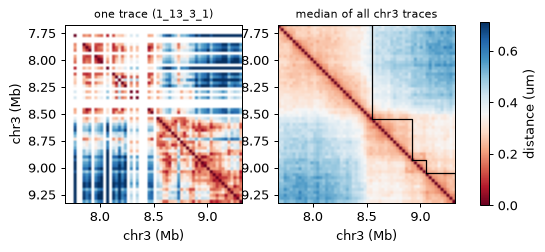

In [19]:
chr3 = subsets['cd.get_chrom("chr3")']
stats = chr3.spots.groupby("trace_id", observed=True)["bin_id"].agg(["size", "nunique"])
tid = stats[stats["size"] == stats["nunique"]]["size"].idxmax()
d = cd.compute_distances(trace_id=tid)
ids = np.flatnonzero(chrom_of_bin.to_numpy() == "chr3")
local = np.searchsorted(ids, cd.get_trace(tid).spots["bin_id"].to_numpy())
single = np.full((60, 60), np.nan); single[np.ix_(local, local)] = d
print(f"trace {tid}: {d.shape[0]} spots, distance matrix {d.shape}")

mb = cd.bins.loc[ids, "start"].to_numpy() / 1e6
ext = [mb[0], mb[-1] + 0.025, mb[-1] + 0.025, mb[0]]
fig, axes = plt.subplots(1, 2, figsize=(7, 3.3))
for ax, m, title in [(axes[0], single, f"one trace ({tid})"), (axes[1], cd.binm["median_distance_um"][ids], "median of all chr3 traces")]:
    im = ax.imshow(m, cmap="RdBu", vmin=0, vmax=np.nanpercentile(cd.binm["median_distance_um"][ids], 98) * 1.3, extent=ext)
    ax.set_title(title, fontsize=9); ax.set_xlabel("chr3 (Mb)")
for _, r in level1.iterrows():
    a, b = r["start"] / 1e6, r["end"] / 1e6
    axes[1].plot([a, b, b], [a, a, b], color="k", lw=1)
axes[0].set_ylabel("chr3 (Mb)")
fig.colorbar(im, ax=axes, shrink=0.8, label="distance (um)")
plt.show()

## Cell positions: `cell_positions`, `set_cell_positions`

Where a cell sits is cell-level data: `cells` columns (`centroid_x`, `centroid_y` [, `centroid_z`]) plus a
record in `uns["cell_spatial"]` that says what they are (unit, frame, measured or inferred, source).
`from_fofct` registered the cell-table centroids:

In [20]:
pos = cd.cell_positions()
print(pos.attrs["cell_spatial"])
pos.head(3)

{'x_col': 'centroid_x', 'y_col': 'centroid_y', 'ndim': 2, 'status': 'measured', 'unit': 'micron', 'source': 'FOF-CT cell table Cent_ROI_x / Cent_ROI_y [/ Cent_ROI_z]'}


,x,y
cell_id,,
0_1,170.079,18.531
0_2,155.510,26.151
0_3,25.481,34.890


The record does not say yet which frame the centroids are in.  The DNA spots give an independent estimate —
the mean of each cell's spots — which we store as a second position set (3-D, `inferred`, with its source).
Cell ids start with the field of view, so positions are local to a FOV (`region_col="fov"`).

In [21]:
cd.cells["fov"] = cd.cells.index.str.split("_").str[0]
spot_mean = pd.DataFrame(cd.coords, columns=["x", "y", "z"]).groupby(cd.spots["cell_id"].astype(str).to_numpy()).mean()
cd.set_cell_positions(spot_mean, key="dna_mean", unit="micron", frame="fov", region_col="fov",
                      in_coords_frame=True, status="inferred", source="mean of the cell's DNA seqFISH+ spots",
                      method="mean")
both = cd.cell_positions().join(cd.cell_positions("dna_mean"), rsuffix="_dna")
offset = np.hypot(both["x"] - both["x_dna"], both["y"] - both["y_dna"])
radius = np.sqrt(cd.cells["nucleus_area_um2"] / np.pi)
print(f"cell-table centroid vs DNA-spot mean: median {offset.median():.2f} um (max {offset.max():.2f}); "
      f"nucleus radius median {radius.median():.1f} um")
print("position sets:", list(cd.uns["cell_spatial"]), "| new columns:", [c for c in cd.cells.columns if c.startswith("dna_mean")])

cell-table centroid vs DNA-spot mean: median 0.50 um (max 1.58); nucleus radius median 7.4 um
position sets: ['default', 'dna_mean'] | new columns: ['dna_mean_centroid_x', 'dna_mean_centroid_y', 'dna_mean_centroid_z']


The two agree to half a micron, well inside a nucleus, so the cell-table centroids share the frame of
`coords`.  Re-registering the existing columns records that (`positions=None, columns=[...]`):

{'x_col': 'centroid_x', 'y_col': 'centroid_y', 'ndim': 2, 'unit': 'micron', 'frame': 'fov', 'region_col': 'fov', 'in_coords_frame': True, 'status': 'measured', 'source': 'FOF-CT cell table Cent_ROI_x / Cent_ROI_y'}


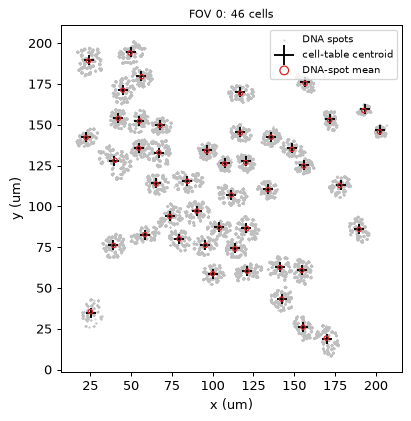

In [22]:
cd.set_cell_positions(columns=["centroid_x", "centroid_y"], unit="micron", frame="fov", region_col="fov",
                      in_coords_frame=True, source="FOF-CT cell table Cent_ROI_x / Cent_ROI_y")
print(cd.cell_positions().attrs["cell_spatial"])

fov0 = cd.cells.index[cd.cells["fov"] == "0"]
sub = cd.get_cells(fov0)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(sub.coords[:, 0], sub.coords[:, 1], s=0.05, c="0.75", rasterized=True, label="DNA spots")
p = cd.cell_positions().loc[fov0]; q = cd.cell_positions("dna_mean").loc[fov0]
ax.scatter(p["x"], p["y"], marker="+", s=60, c="k", label="cell-table centroid")
ax.scatter(q["x"], q["y"], s=12, facecolors="none", edgecolors="C3", label="DNA-spot mean")
ax.set_aspect("equal"); ax.set_xlabel("x (um)"); ax.set_ylabel("y (um)")
ax.set_title(f"FOV 0: {len(fov0)} cells", fontsize=9); ax.legend(fontsize=8, markerscale=2, loc="upper right")
plt.show()

## Export and a round trip

`to_dataframe()` gives the flat structure table (one row per spot: loci, x, y, z and the spot columns),
`to_anndata()` the cell-level part (`cells` as `obs`, `cellm` as `obsm`), `to_fofct()` a FOF-CT table.
`write()` keeps everything; reading the store back returns every piece added above.

In [23]:
display(cd.to_dataframe().head(3))
adata = cd.to_anndata()
print("to_anndata:", adata.shape, "obsm:", list(adata.obsm))

path = OUT / "takei2021_basics.chromdata.zarr"
cd.write(path)
back = ChromData.read(path)
checks = {
    "bin_tracks": back.bin_tracks.equals(cd.bin_tracks),
    "binm": np.array_equal(back.binm["median_distance_um"], cd.binm["median_distance_um"], equal_nan=True),
    "cellm": np.array_equal(back.cellm["rna_pca"], cd.cellm["rna_pca"]),
    "traces": back.traces.sort_index().equals(cd.traces.sort_index()),
    "intervals": sorted(back.intervals) == sorted(cd.intervals),
    "results + provenance": back.results.record("tads.arcfish").provenance == rec.provenance,
    "cell positions": back.cell_positions("dna_mean").equals(cd.cell_positions("dna_mean")),
    "spot tracks (sorted by spot_id)": np.allclose(
        back.spot_tracks["dist_to_trace_centre_um"].to_numpy()[np.argsort(back.spots["spot_id"].to_numpy())],
        cd.spot_tracks["dist_to_trace_centre_um"].to_numpy()[np.argsort(cd.spots["spot_id"].to_numpy())]),
}
print(path.relative_to(REPO), checks)

,chrom,start,end,x,y,z,trace_id,spot_id,cell_id,extra_cell_roi_id
0,chr1,135625000,135650000,176.998,15.132,2.821,0_1_1_0,705144,0_1,0
1,chr1,135650000,135675000,176.953,15.056,2.771,0_1_1_0,705145,0_1,0
2,chr1,135650000,135675000,165.263,21.032,2.931,0_1_1_1,705146,0_1,0


to_anndata: (201, 0) obsm: ['rna_pca']


tutorials/_out/chromdata_basics/takei2021_basics.chromdata.zarr {'bin_tracks': True, 'binm': True, 'cellm': True, 'traces': True, 'intervals': True, 'results + provenance': True, 'cell positions': True, 'spot tracks (sorted by spot_id)': True}


## Next steps

- `chromdata_stores` — the `.chromdata.zarr` store: row order, backed reads of one cell or chromosome,
  streaming writes, linked contact maps and AnnData, embedded copies and the public atlas over HTTP.
- `import_fofct` — more on FOF-CT import and export.
- `tad_calling`, `loop_calling`, `compartment` — the structure callers that fill `intervals` and `results`.
- `fish_imputation` — filling in undetected loci (`uchrom.pp.impute`).